PROJECT 04: FIRST MACHINE LEARNING CLASSIFIER

Titanic Survival Prediction using Decision Tree Classifier

Internship: InternCircle Data Science & AI Internship

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Titanic dataset
titanic = sns.load_dataset('titanic')

# Display first five rows
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# Select the required columns
data = titanic[['survived', 'pclass', 'sex', 'age', 'fare']].copy()

# Display the first five rows
data.head()

,survived,pclass,sex,age,fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [3]:
# Check dataset shape
print("Dataset Shape:", data.shape)

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Check data types
print("\nData Types:")
print(data.dtypes)

Dataset Shape: (891, 5)

Missing Values:
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64

Data Types:
survived      int64
pclass        int64
sex          object
age         float64
fare        float64
dtype: object


In [4]:
# Fill missing age values with the median
data['age'] = data['age'].fillna(data['age'].median())

# Convert sex into numerical values
data['sex'] = data['sex'].map({
    'male': 0,
    'female': 1
})

# Check missing values after cleaning
print("Missing values after cleaning:")
print(data.isnull().sum())

# Display cleaned data
data.head()

Missing values after cleaning:
survived    0
pclass      0
sex         0
age         0
fare        0
dtype: int64


,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [5]:
from sklearn.model_selection import train_test_split

# Define features (X)
X = data[['pclass', 'sex', 'age', 'fare']]

# Define target (y)
y = data['survived']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (712, 4)
Testing features: (179, 4)

Training target: (712,)
Testing target: (179,)


In [6]:
from sklearn.metrics import accuracy_score

# Find the most common survival outcome in training data
most_common_class = y_train.mode()[0]

# Predict the same outcome for every test passenger
baseline_predictions = [most_common_class] * len(y_test)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Most common class:", most_common_class)
print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")

Most common class: 0
Baseline Accuracy: 61.45 %


In [7]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train the model using training data
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [8]:
from sklearn.metrics import accuracy_score

# Predict survival using test data
y_pred = model.predict(X_test)

# Calculate model accuracy
model_accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(model_accuracy * 100, 2), "%")

Decision Tree Accuracy: 77.65 %


Confusion Matrix:
[[105   5]
 [ 35  34]]


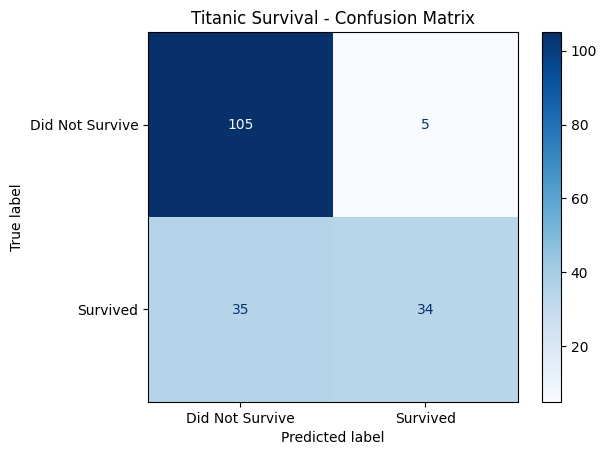

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Did Not Survive', 'Survived']
)

display.plot(cmap='Blues')
plt.title("Titanic Survival - Confusion Matrix")
plt.show()

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Store accuracy results
train_accuracies = []
test_accuracies = []
depths = range(1, 13)

# Train models with different depths
for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    # Training accuracy
    train_pred = tree.predict(X_train)
    train_accuracies.append(
        accuracy_score(y_train, train_pred)
    )

    # Testing accuracy
    test_pred = tree.predict(X_test)
    test_accuracies.append(
        accuracy_score(y_test, test_pred)
    )

# Display results
for depth, train_acc, test_acc in zip(
    depths, train_accuracies, test_accuracies
):
    print(
        f"Depth: {depth:2d} | "
        f"Training Accuracy: {train_acc:.2%} | "
        f"Testing Accuracy: {test_acc:.2%}"
    )

Depth:  1 | Training Accuracy: 78.93% | Testing Accuracy: 77.65%
Depth:  2 | Training Accuracy: 80.48% | Testing Accuracy: 75.98%
Depth:  3 | Training Accuracy: 82.58% | Testing Accuracy: 79.33%
Depth:  4 | Training Accuracy: 83.15% | Testing Accuracy: 77.65%
Depth:  5 | Training Accuracy: 86.52% | Testing Accuracy: 76.54%
Depth:  6 | Training Accuracy: 87.92% | Testing Accuracy: 77.65%
Depth:  7 | Training Accuracy: 88.20% | Testing Accuracy: 77.09%
Depth:  8 | Training Accuracy: 90.45% | Testing Accuracy: 77.65%
Depth:  9 | Training Accuracy: 91.71% | Testing Accuracy: 78.21%
Depth: 10 | Training Accuracy: 92.42% | Testing Accuracy: 76.54%
Depth: 11 | Training Accuracy: 93.12% | Testing Accuracy: 78.77%
Depth: 12 | Training Accuracy: 93.68% | Testing Accuracy: 81.01%


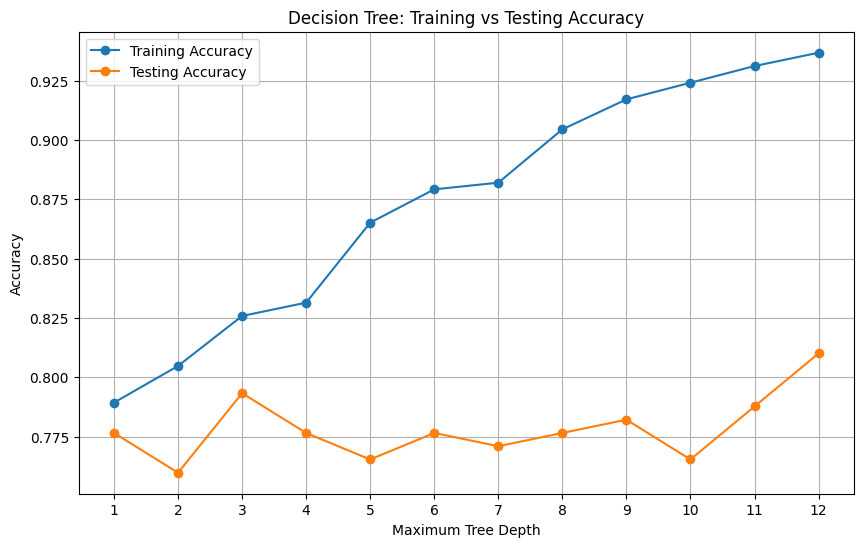

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    depths,
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depths,
    test_accuracies,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Training vs Testing Accuracy')
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

key takeaway:A deeper Decision Tree does not always guarantee better performance on unseen data. As tree depth increases, training accuracy generally improves, but testing accuracy may fluctuate. This demonstrates the risk of overfitting.

  Feature  Importance
1     sex    0.598570
0  pclass    0.208209
3    fare    0.098815
2     age    0.094407


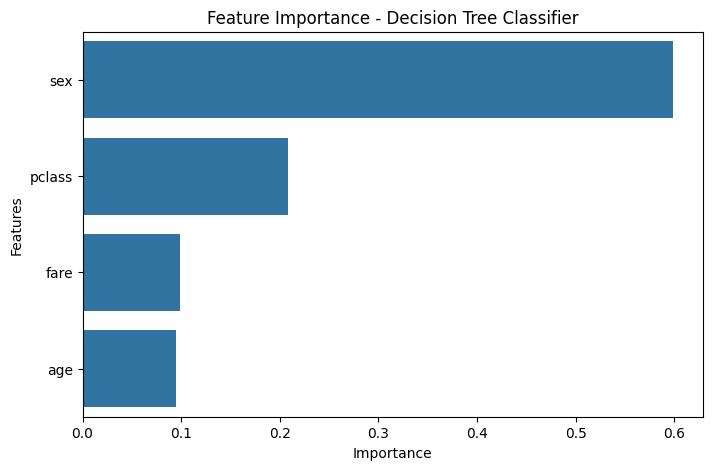

In [12]:
# Get feature importance values
importance = model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Decision Tree Classifier')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

### Feature Importance Analysis

The feature importance analysis shows that sex is the most influential feature in predicting Titanic passenger survival, with an importance score of 0.598570 (approximately 59.86%).

Passenger class is the second most important feature, contributing approximately 20.82%. Fare contributes 9.88%, while age contributes 9.44%.

**Observation:** The model relies most heavily on sex and passenger class when predicting survival.

These importance scores describe how the trained Decision Tree uses the features. They do not prove that the features directly caused survival outcomes.

In [13]:
from sklearn.metrics import mean_squared_error

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", round(mse, 4))

Mean Squared Error: 0.2235


## Final Model Evaluation

The Decision Tree Classifier was evaluated using an independent test dataset containing 179 passenger records.

### Evaluation Results

- **Baseline Accuracy:** 61.45%
- **Decision Tree Accuracy:** 77.65%
- **Mean Squared Error:** 0.2235
- **Correct Predictions:** 139
- **Incorrect Predictions:** 40

### Conclusion

The Decision Tree Classifier achieved 77.65% accuracy, outperforming the baseline model by 16.20 percentage points.

The confusion matrix showed that the model predicted passengers who did not survive more accurately than passengers who survived.

The feature importance analysis identified sex as the most influential feature, followed by passenger class, fare, and age.

The experiment with different tree depths demonstrated that increasing model complexity generally improved training accuracy but did not consistently improve testing accuracy. This highlights the risk of overfitting.

### Limitations

1. The Titanic dataset is relatively small, containing only 891 records.
2. Missing age values were replaced with the median, which may not represent every passenger accurately.
3. Only four features were used for prediction.
4. Results depend on the selected train/test split.
5. Feature importance does not establish causation.
6. Accuracy alone does not fully describe model performance, especially when survival classes are imbalanced.

### What I Learned

- How to split data into training and testing sets.
- How to train a Decision Tree using Scikit-Learn.
- How to calculate baseline accuracy.
- How to evaluate a classifier using accuracy, confusion matrix, and MSE.
- How to identify important features.
- How to understand and visualize overfitting.